# LAB: DCNN on a Dataset of Your Choice
## Dataset: Cat Adoption Metadata



## 1. Import libraries



In [3]:
import os
import ast
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler, LabelEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay

import tensorflow as tf
from tensorflow.keras import layers, models, callbacks

print("TensorFlow:", tf.__version__)

TensorFlow: 2.21.0


## 2. Load the dataset



In [4]:
file_path = "cats(1).csv"

column_names = [
    "record_id", "pet_id", "listing_url", "animal_type", "age",
    "sex", "size", "coat_length", "breed", "photos", "photo_urls"
]

df = pd.read_csv(file_path, header=None, names=column_names)
print("Dataset shape:", df.shape)
display(df.head())
print("\\nMissing values:")
display(df.isna().sum())

Dataset shape: (298, 11)


,record_id,pet_id,listing_url,animal_type,age,sex,size,coat_length,breed,photos,photo_urls
0,48076,26989072,https://www.petfinder.com/cat/jupiter-26989072...,Cat,Adult,Male,Medium,NaN,Persian,[{'small': 'https://dl5zpyw5k3jeb.cloudfront.n...,['https://dl5zpyw5k3jeb.cloudfront.net/photos/...
1,48077,26979449,https://www.petfinder.com/cat/elliot-26979449/...,Cat,Adult,Male,Medium,Long,Persian,[{'small': 'https://dl5zpyw5k3jeb.cloudfront.n...,['https://dl5zpyw5k3jeb.cloudfront.net/photos/...
2,48078,26974960,https://www.petfinder.com/cat/zarro-26974960/m...,Cat,Adult,Male,Small,Medium,Persian,[{'small': 'https://dl5zpyw5k3jeb.cloudfront.n...,['https://dl5zpyw5k3jeb.cloudfront.net/photos/...
3,48079,26973986,https://www.petfinder.com/cat/snickers-2697398...,Cat,Adult,Female,Small,NaN,Persian,[{'small': 'https://dl5zpyw5k3jeb.cloudfront.n...,['https://dl5zpyw5k3jeb.cloudfront.net/photos/...
4,48080,26972127,https://www.petfinder.com/cat/ms-bigglesworth-...,Cat,Senior,Female,Small,Long,Persian,[{'small': 'https://dl5zpyw5k3jeb.cloudfront.n...,['https://dl5zpyw5k3jeb.cloudfront.net/photos/...


\nMissing values:


record_id       0
pet_id          0
listing_url     0
animal_type     0
age             0
sex             0
size            0
coat_length    96
breed           0
photos          0
photo_urls      0
dtype: int64

## 3. Prepare features and target


In [5]:
# Keep rows with a known target
data = df.dropna(subset=["breed"]).copy()

target_col = "breed"
feature_cols = ["animal_type", "age", "sex", "size", "coat_length"]
X = data[feature_cols]
y_text = data[target_col].astype(str)

label_encoder = LabelEncoder()
y = label_encoder.fit_transform(y_text)
class_names = label_encoder.classes_
print("Classes:", list(class_names))
print(y_text.value_counts())

X_train_df, X_test_df, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

categorical_features = ["animal_type", "age", "sex", "size", "coat_length"]
preprocessor = ColumnTransformer(
    transformers=[
        ("categorical", Pipeline(steps=[
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
        ]), categorical_features)
    ],
    remainder="drop"
)

X_train = preprocessor.fit_transform(X_train_df)
X_test = preprocessor.transform(X_test_df)

# Standardize encoded input features using training data only
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train).astype("float32")
X_test = scaler.transform(X_test).astype("float32")

# Conv1D expects input shape: (number of features, channels)
X_train_cnn = X_train[..., np.newaxis]
X_test_cnn = X_test[..., np.newaxis]

num_classes = len(class_names)
y_train_cat = tf.keras.utils.to_categorical(y_train, num_classes)
y_test_cat = tf.keras.utils.to_categorical(y_test, num_classes)

print("Training shape:", X_train_cnn.shape)
print("Testing shape:", X_test_cnn.shape)

Classes: ['Persian', 'Pixiebob', 'Ragamuffin']
breed
Persian       149
Pixiebob      111
Ragamuffin     38
Name: count, dtype: int64
Training shape: (238, 14, 1)
Testing shape: (60, 14, 1)


## 4. Build DCNN configurations


In [6]:
def build_dcnn(input_shape, num_classes, config="A"):
    model = models.Sequential()
    model.add(layers.Input(shape=input_shape))

    if config == "A":
        model.add(layers.Conv1D(32, kernel_size=3, padding="same", activation="relu"))
        model.add(layers.MaxPooling1D(pool_size=2))
        model.add(layers.Flatten())
        model.add(layers.Dense(32, activation="relu"))
    elif config == "B":
        model.add(layers.Conv1D(32, kernel_size=3, padding="same", activation="relu"))
        model.add(layers.MaxPooling1D(pool_size=2))
        model.add(layers.Conv1D(64, kernel_size=3, padding="same", activation="relu"))
        model.add(layers.GlobalMaxPooling1D())
        model.add(layers.Dense(64, activation="relu"))
    else:
        raise ValueError("config must be 'A' or 'B'")

    model.add(layers.Dropout(0.25))
    model.add(layers.Dense(num_classes, activation="softmax"))

    model.compile(
        optimizer="adam",
        loss="categorical_crossentropy",
        metrics=["accuracy"]
    )
    return model

print("Configuration A:")
build_dcnn((X_train_cnn.shape[1], 1), num_classes, "A").summary()
print("\\nConfiguration B:")
build_dcnn((X_train_cnn.shape[1], 1), num_classes, "B").summary()

Configuration A:


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1d (Conv1D)                 │ (None, 14, 32)         │           128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d (MaxPooling1D)    │ (None, 7, 32)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 224)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │         7,200 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 3)              │            99 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 7,427 (29.01 KB)

 Trainable params: 7,427 (29.01 KB)

...

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1d_1 (Conv1D)               │ (None, 14, 32)         │           128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_1 (MaxPooling1D)  │ (None, 7, 32)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_2 (Conv1D)               │ (None, 7, 64)          │         6,208 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_max_pooling1d            │ (None, 64)             │             0 │
│ (GlobalMaxPooling1D)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 3)              │           195 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 10,691 (41.76 KB)

 Trainable params: 10,691 (41.76 KB)

 Non-trainable params: 0 (0.00 B)

## 5. Train and compare configurations and epoch counts



In [7]:
results = []
histories = {}
trained_models = {}

epoch_options = [10, 20, 30]
config_options = ["A", "B"]

for config in config_options:
    for epoch_count in epoch_options:
        print(f"Training config={config}, max_epochs={epoch_count}")
        tf.keras.utils.set_random_seed(42)

        model = build_dcnn((X_train_cnn.shape[1], 1), num_classes, config)
        early_stop = callbacks.EarlyStopping(
            monitor="val_loss", patience=5, restore_best_weights=True
        )

        history = model.fit(
            X_train_cnn, y_train_cat,
            validation_split=0.20,
            epochs=epoch_count,
            batch_size=16,
            callbacks=[early_stop],
            verbose=0
        )

        test_loss, test_accuracy = model.evaluate(
            X_test_cnn, y_test_cat, verbose=0
        )

        key = f"{config}_{epoch_count}"
        histories[key] = history.history
        trained_models[key] = model

        results.append({
            "configuration": config,
            "epochs_requested": epoch_count,
            "epochs_trained": len(history.history["loss"]),
            "test_accuracy": test_accuracy,
            "test_loss": test_loss,
            "best_val_accuracy": max(history.history["val_accuracy"]),
            "minimum_val_loss": min(history.history["val_loss"])
        })

results_df = pd.DataFrame(results).sort_values(
    ["configuration", "epochs_requested"]
).reset_index(drop=True)
display(results_df)

Training config=A, max_epochs=10
Training config=A, max_epochs=20
Training config=A, max_epochs=30
Training config=B, max_epochs=10
Training config=B, max_epochs=20
Training config=B, max_epochs=30


,configuration,epochs_requested,epochs_trained,test_accuracy,test_loss,best_val_accuracy,minimum_val_loss
0,A,10,10,0.783333,0.603591,0.708333,0.653824
1,A,20,19,0.783333,0.590240,0.708333,0.639048
2,A,30,19,0.783333,0.590240,0.708333,0.639048
3,B,10,10,0.750000,0.603617,0.666667,0.724504
4,B,20,15,0.750000,0.603617,0.687500,0.724504
5,B,30,15,0.750000,0.603617,0.687500,0.724504


## 6. Compare test accuracy


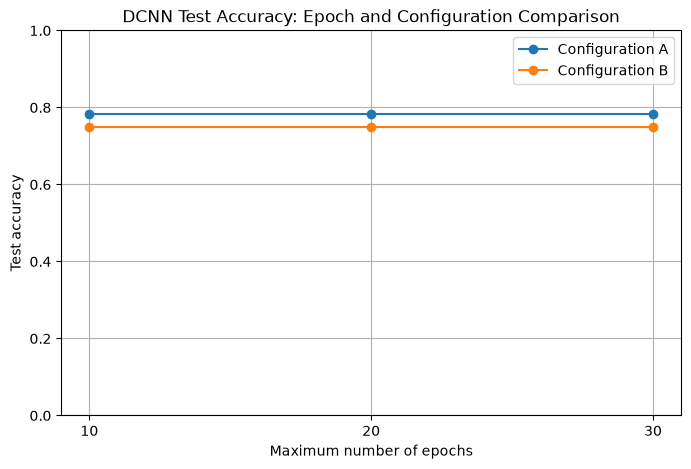

Best experiment:


,value
configuration,A
epochs_requested,10
epochs_trained,10
test_accuracy,0.783333
test_loss,0.603591
best_val_accuracy,0.708333
minimum_val_loss,0.653824


In [8]:
plt.figure(figsize=(8, 5))
for config in config_options:
    subset = results_df[results_df["configuration"] == config]
    plt.plot(
        subset["epochs_requested"], subset["test_accuracy"],
        marker="o", label=f"Configuration {config}"
    )
plt.xlabel("Maximum number of epochs")
plt.ylabel("Test accuracy")
plt.title("DCNN Test Accuracy: Epoch and Configuration Comparison")
plt.xticks(epoch_options)
plt.ylim(0, 1)
plt.grid(True)
plt.legend()
plt.show()

best_row = results_df.loc[results_df["test_accuracy"].idxmax()]
print("Best experiment:")
display(best_row.to_frame(name="value"))

## 7. Training and validation accuracy/loss


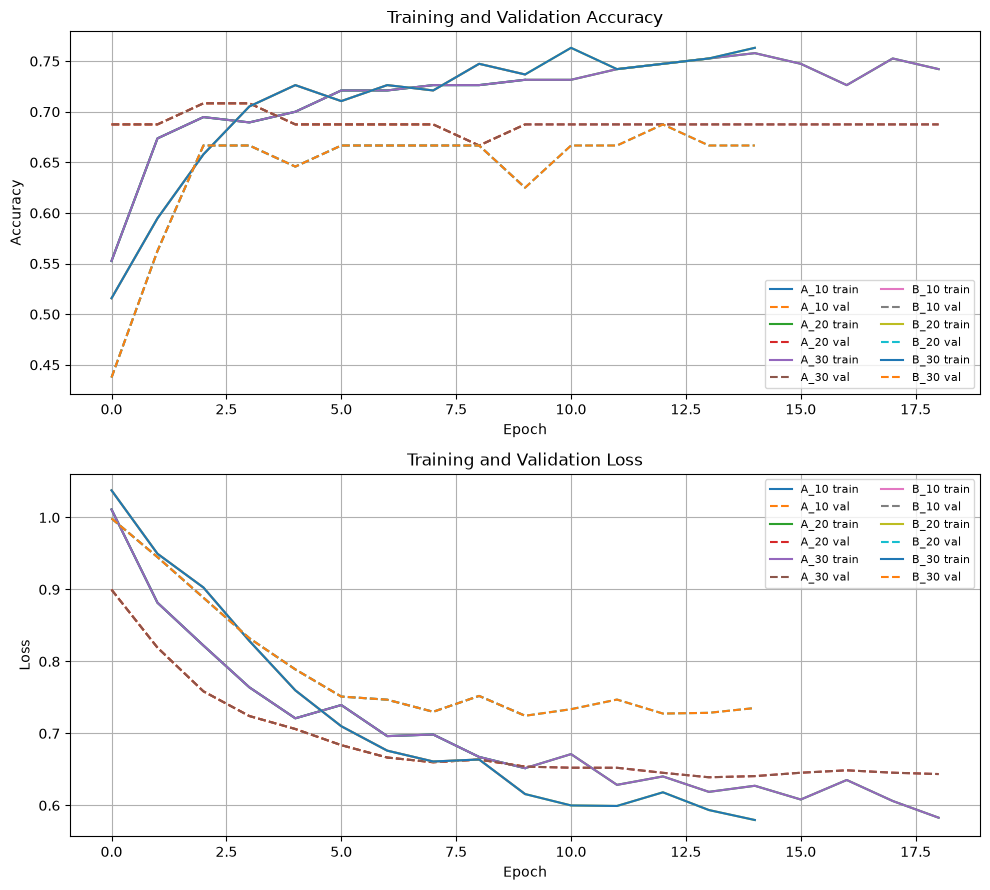

In [9]:
fig, axes = plt.subplots(2, 1, figsize=(10, 9))

for key, history in histories.items():
    axes[0].plot(history["accuracy"], label=f"{key} train")
    axes[0].plot(history["val_accuracy"], linestyle="--", label=f"{key} val")
axes[0].set_title("Training and Validation Accuracy")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy")
axes[0].grid(True)
axes[0].legend(ncol=2, fontsize=8)

for key, history in histories.items():
    axes[1].plot(history["loss"], label=f"{key} train")
    axes[1].plot(history["val_loss"], linestyle="--", label=f"{key} val")
axes[1].set_title("Training and Validation Loss")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Loss")
axes[1].grid(True)
axes[1].legend(ncol=2, fontsize=8)

plt.tight_layout()
plt.show()

## 8. Evaluate the best model and show predictions



Best experiment: A_10
Test accuracy: 0.7833
\nClassification report:
              precision    recall  f1-score   support

     Persian       0.74      0.97      0.84        30
    Pixiebob       0.85      0.77      0.81        22
  Ragamuffin       1.00      0.12      0.22         8

    accuracy                           0.78        60
   macro avg       0.86      0.62      0.62        60
weighted avg       0.82      0.78      0.75        60



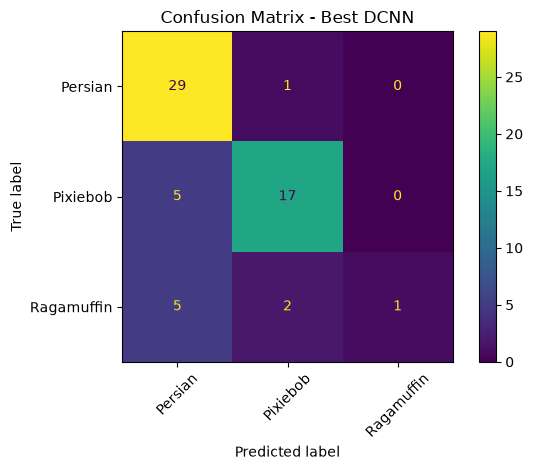

,animal_type,age,sex,size,coat_length,actual_breed,predicted_breed,correct
0,Cat,Adult,Male,Medium,NaN,Persian,Persian,True
1,Cat,Adult,Female,Medium,Long,Persian,Persian,True
2,Cat,Adult,Female,Medium,NaN,Persian,Persian,True
3,Cat,Baby,Male,Small,NaN,Persian,Persian,True
4,Cat,Adult,Male,Medium,Long,Persian,Persian,True
5,Cat,Adult,Male,Medium,Long,Persian,Persian,True
6,Cat,Adult,Male,Medium,NaN,Pixiebob,Persian,False
7,Cat,Young,Male,Small,NaN,Persian,Persian,True
8,Cat,Baby,Female,Large,Medium,Ragamuffin,Ragamuffin,True
9,Cat,Adult,Male,Medium,Long,Persian,Persian,True


In [10]:
best_key = results_df.loc[results_df["test_accuracy"].idxmax()].apply(str)
best_config = results_df.loc[results_df["test_accuracy"].idxmax(), "configuration"]
best_epochs = int(results_df.loc[results_df["test_accuracy"].idxmax(), "epochs_requested"])
best_key = f"{best_config}_{best_epochs}"
best_model = trained_models[best_key]

probabilities = best_model.predict(X_test_cnn, verbose=0)
predicted_ids = np.argmax(probabilities, axis=1)
predicted_labels = label_encoder.inverse_transform(predicted_ids)
actual_labels = label_encoder.inverse_transform(y_test)

print("Best experiment:", best_key)
print("Test accuracy:", round(accuracy_score(y_test, predicted_ids), 4))
print("\\nClassification report:")
print(classification_report(
    y_test, predicted_ids, labels=np.arange(num_classes),
    target_names=class_names, zero_division=0
))

ConfusionMatrixDisplay.from_predictions(
    y_test, predicted_ids,
    labels=np.arange(num_classes),
    display_labels=class_names,
    xticks_rotation=45
)
plt.title("Confusion Matrix - Best DCNN")
plt.tight_layout()
plt.show()

prediction_df = X_test_df.reset_index(drop=True).copy()
prediction_df["actual_breed"] = actual_labels
prediction_df["predicted_breed"] = predicted_labels
prediction_df["correct"] = prediction_df["actual_breed"] == prediction_df["predicted_breed"]
display(prediction_df.head(15))